## Including a crop model

In [1]:
""" 
Imports needed for running the code
"""
# Ignore warnings during ODE solving
# Typically such warnings should be checked,
# but for the current exercise it is not important
import warnings
warnings.filterwarnings("ignore")

import os

from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import greenlight

In [2]:
crop_definition = {
    "W": {
        "definition": "LUE * (1 - exp(-k*LAI)) * iSun * 1e-6",
        "type": "state",
        "init": "75"
    },
     "LUE": {
        "definition": "4.3",
        "type": "const"
    },
     "k": {
        "definition": "0.7",
        "type": "const"
    },
     "iSun": {
        "definition": "iSun",
        "type": "input"
    },
    "LAI": {
        "definition": "W * fLeaves * SLA / 10000",
        "type": "aux"
    },
     "fLeaves": {
        "definition": "0.3",
        "type": "const"
    },
     "SLA": {
        "definition": "200",
        "type": "const"
    }   
 }

n_days = 100

options = {
    "options": {
        "t_start":"0",
        "t_end": str(n_days * 24 * 60 * 60),
        "output_step": "300",
        "t_eval": "300"
    }
}

crop_mdl = greenlight.GreenLight(
    base_path=os.getcwd(), 
    input_prompt=[crop_definition, os.path.join("input", "example_weather.csv"), options], 
    output_path=os.path.join("output", "crop_output.csv")
)
crop_mdl.run()





Loading model from input\example_weather.csv
Simulation started at time (ISO format): 2026-10-19T14:57:30.399999
Running: 100.00%

Simulation complete at time (ISO format): 2026-10-19T14:57:32.781849
Simulated 99.99652777777777 days
Elapsed time: 2.3818492889404297 seconds
Output saved to file output\crop_output.csv
Model structure log saved to output\crop_output_model_struct_log.json
Simulation log saved to output\crop_output_simulation_log.txt


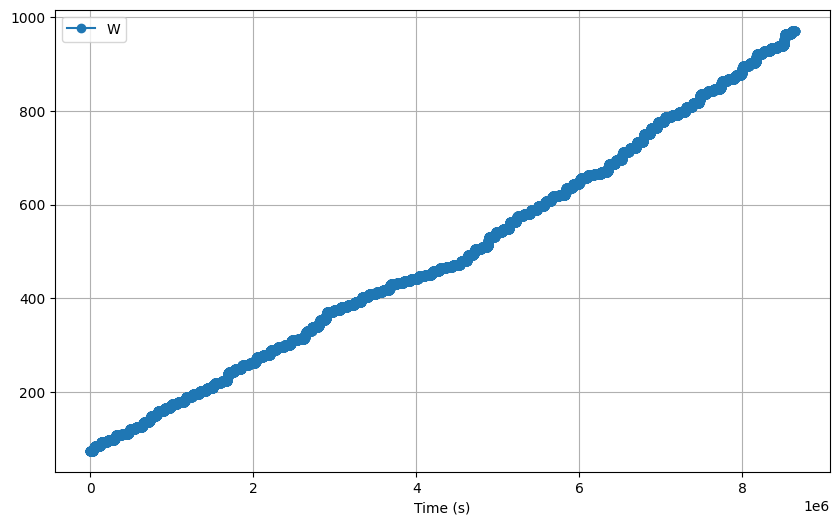

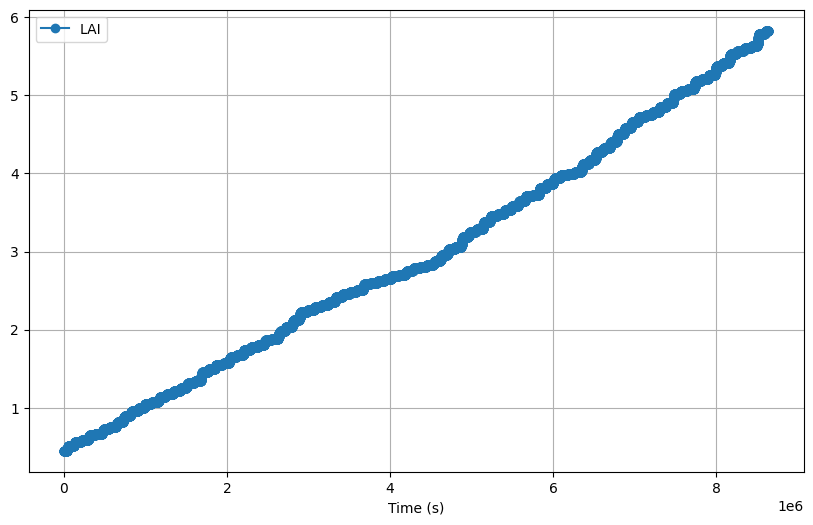

In [3]:
# Load simulation result
crop_output = pd.read_csv(os.path.join("output", "crop_output.csv"), header=[0,1,2], low_memory=False)

# Display
def display_output(output_df, chosen_vars, titles, ylabels, line_style):
    axes = []
    
    for vars_to_plot, title, ylabel in zip(chosen_vars, titles, ylabels):
        fig = plt.figure(figsize=(10, 6))
        ax = fig.add_subplot(111)
        
        for var in vars_to_plot:
            ax.plot(output_df["Time"], output_df[var], line_style, label=var)
        
        ax.set_xlabel("Time (s)")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.legend()
        ax.grid(True)
        axes.append(ax)
        plt.show()

    return axes
    
axes = display_output(crop_output, [["W"], ["LAI"]], ["", ""], ["", ""], '-o')

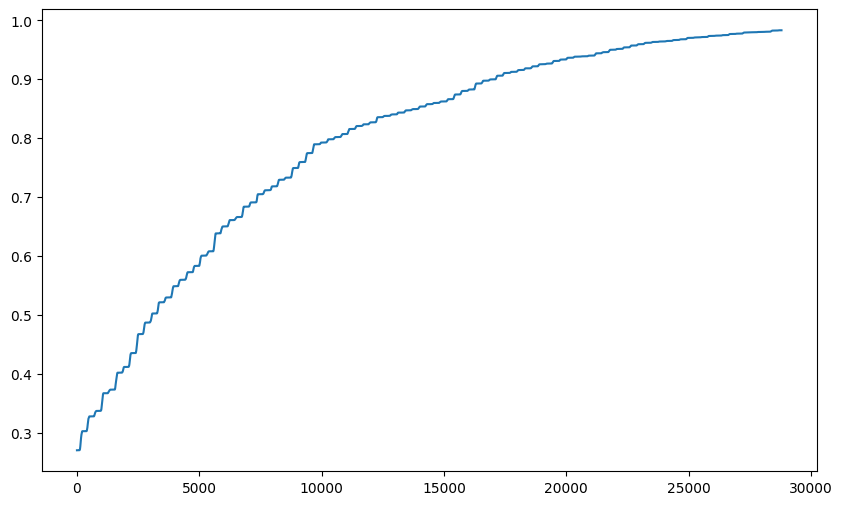

In [4]:
import numpy as np

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)
ax.plot(1 - np.exp(-0.7*crop_output["LAI"]))